# Narrative Analysis — Learning With(out) AI

This notebook produces the statistics and visualizations used in the Main Findings section of README.md.

It uses the two primary datasets from the data folder and follows the data-loading approach in EDA.ipynb.

The notebook calculates correlations, summarizes satisfaction ratings, and generates figures for the findings.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

df1 = pd.read_csv("data/student_ai_tool_usage_dataset.csv")
df2 = pd.read_csv("data/ai_student_impact_dataset (1).csv")

# Create the folder for figures
os.makedirs("figures", exist_ok=True)

FIGURE_DIR = "figures"

print("Primary Dataset 1 shape:", df1.shape)
print("Primary Dataset 2 shape:", df2.shape)

Primary Dataset 1 shape: (200, 8)
Primary Dataset 2 shape: (50000, 16)


# Prepare the data

Calculate GPA change by subtracting pre-semester GPA from post-semester GPA.

A positive value means GPA increased, while a negative value means GPA decreased.

In [2]:
# Clean purpose values using the same approach as EDA.ipynb
df1["purpose"] = df1["purpose"].str.lower().str.strip()

df1["purpose"] = df1["purpose"].replace(
    "chatgpt is used for many different tasks.", "other"
)

# Calculate GPA change
df2["GPA_Change"] = (
    df2["Post_Semester_GPA"] - df2["Pre_Semester_GPA"]
)

print("Mean GPA change:", df2["GPA_Change"].mean())
print("Median GPA change:", df2["GPA_Change"].median())

Mean GPA change: 0.20319707999999997
Median GPA change: 0.20399999999999974


# Finding One: Weekly AI usage has little relationship with GPA change

Calculate the correlations between GPA change, weekly generative AI hours, and tool diversity.

Then create a scatterplot to visualize the relationship between weekly AI usage and GPA change.

Correlation between weekly AI hours and GPA change: -0.05
Correlation between tool diversity and GPA change: 0.08


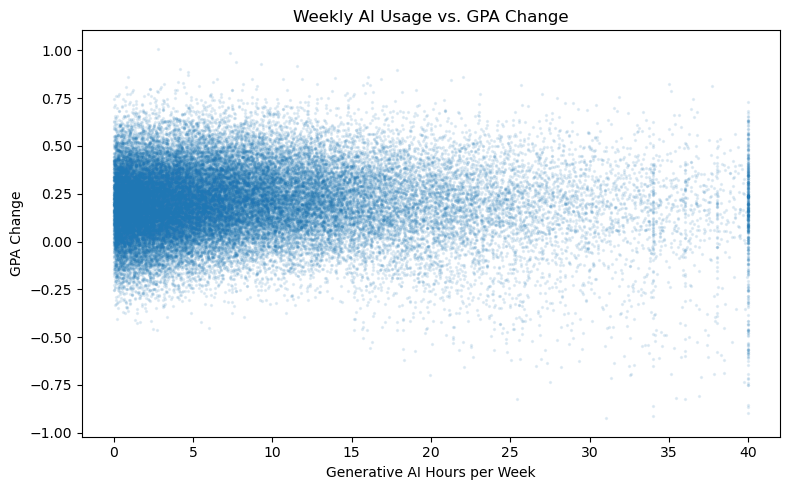

In [3]:
# Calculate correlations
ai_hours_corr = df2[
    ["Weekly_GenAI_Hours", "GPA_Change"]
].corr().iloc[0, 1]

tool_diversity_corr = df2[
    ["Tool_Diversity", "GPA_Change"]
].corr().iloc[0, 1]

print(
    "Correlation between weekly AI hours and GPA change:",
    round(ai_hours_corr, 2)
)

print(
    "Correlation between tool diversity and GPA change:",
    round(tool_diversity_corr, 2)
)

# Create scatterplot
plt.figure(figsize=(8, 5))

plt.scatter(
    df2["Weekly_GenAI_Hours"],
    df2["GPA_Change"],
    s=2,
    alpha=0.1
)

plt.title("Weekly AI Usage vs. GPA Change")
plt.xlabel("Generative AI Hours per Week")
plt.ylabel("GPA Change")

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "ai-hours-vs-gpa-change.png"),
    bbox_inches="tight",
    dpi=300
)

plt.show()

# Finding Two: Traditional study hours have a stronger relationship with GPA change

Compare the correlation between traditional study hours and GPA change with the correlation between weekly AI hours and GPA change.

Create a scatterplot to visualize the relationship.

Correlation between traditional study hours and GPA change: 0.38
Correlation between weekly AI hours and GPA change: -0.05


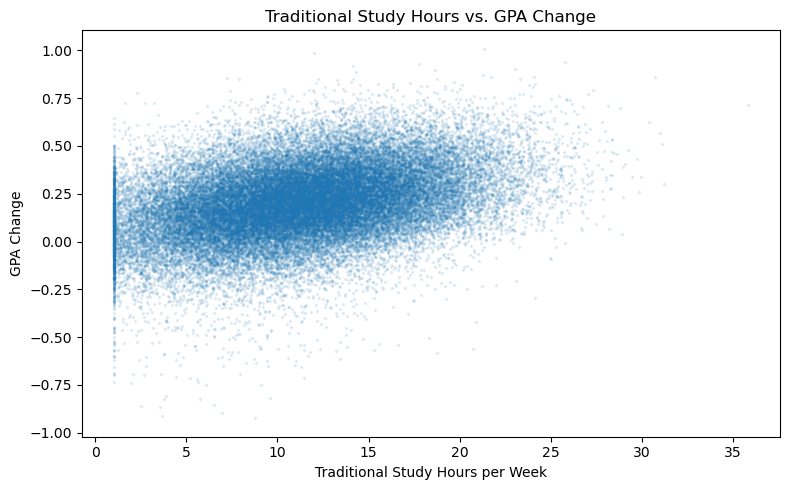

In [4]:
traditional_corr = df2[
    ["Traditional_Study_Hours", "GPA_Change"]
].corr().iloc[0, 1]

print(
    "Correlation between traditional study hours and GPA change:",
    round(traditional_corr, 2)
)

print(
    "Correlation between weekly AI hours and GPA change:",
    round(ai_hours_corr, 2)
)

# Create scatterplot
plt.figure(figsize=(8, 5))

plt.scatter(
    df2["Traditional_Study_Hours"],
    df2["GPA_Change"],
    s=2,
    alpha=0.1
)

plt.title("Traditional Study Hours vs. GPA Change")
plt.xlabel("Traditional Study Hours per Week")
plt.ylabel("GPA Change")

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "traditional-study-hours-vs-gpa-change.png"),
    bbox_inches="tight",
    dpi=300
)

plt.show()

# Finding Three: Most surveyed students reported high satisfaction with AI tools

Calculate the number and percentage of students who gave satisfaction ratings of 4 or 5.

Then visualize the distribution of satisfaction ratings.

Valid satisfaction responses: 200
Average satisfaction: 3.77
Students with satisfaction ratings of 4 or 5: 117
Percentage with satisfaction ratings of 4 or 5: 58.5 %


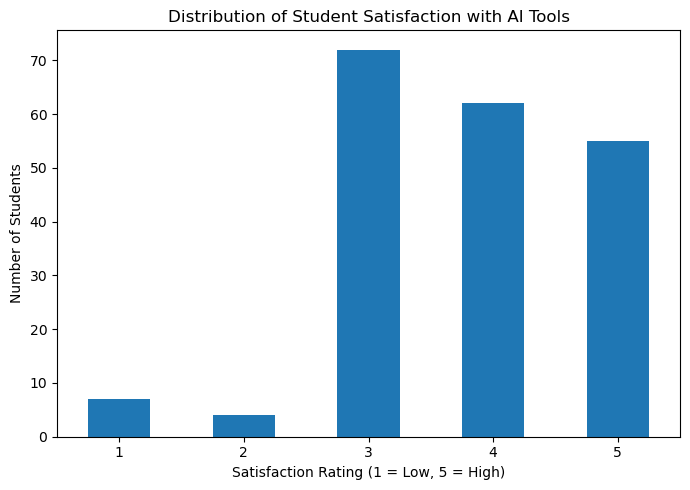

In [5]:
satisfaction = df1["satisfaction_level"].dropna()

high_satisfaction_count = satisfaction.isin([4, 5]).sum()
valid_satisfaction_count = satisfaction.count()

high_satisfaction_percent = (
    high_satisfaction_count / valid_satisfaction_count * 100
)

print("Valid satisfaction responses:", valid_satisfaction_count)
print("Average satisfaction:", round(satisfaction.mean(), 2))

print(
    "Students with satisfaction ratings of 4 or 5:",
    high_satisfaction_count
)

print(
    "Percentage with satisfaction ratings of 4 or 5:",
    round(high_satisfaction_percent, 1), "%"
)

# Plot satisfaction distribution
satisfaction.value_counts().sort_index().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Distribution of Student Satisfaction with AI Tools")
plt.xlabel("Satisfaction Rating (1 = Low, 5 = High)")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "satisfaction-distribution.png"),
    bbox_inches="tight",
    dpi=300
)

plt.show()